# Celeb-DF-v2 face extraction (run once, on Kaggle)

Produces the 224x224 face crops every training run needs. Celeb-DF-v2 is already
mounted here, so nothing is downloaded.

**Before running:** add `reubensuju/celeb-df-v2` via *+ Add Input*, and set
*Settings > Accelerator* to **None** (this is CPU-bound) and *Persistence* to
**Files only** so a reclaimed session keeps its progress.

Runtime is roughly 1-2 hours for all 6,229 videos. Re-running skips whatever is
already done, so a disconnect costs nothing.

## 1. Get the code

In [6]:
# Option A -- clone from GitHub (edit the URL):
REPO = "https://github.com/rahulbhatyogesh/DIP-Project.git"  # e.g. "https://github.com/<you>/dip-hfc-deepfake.git"

import os
import subprocess
import sys
from pathlib import Path

CODE = None

if REPO:
    if not os.path.exists("/kaggle/working/code"):
        subprocess.run(["git", "clone", REPO, "/kaggle/working/code"], check=True)
    CODE = "/kaggle/working/code"
else:
    # Option B -- find whichever mounted input actually holds the package,
    # instead of assuming what Kaggle slugified the dataset title into.
    for hit in Path("/kaggle/input").rglob("models/hfc.py"):
        CODE = str(hit.parents[2])
        break

if CODE is None:
    print("Code not found. Inputs currently mounted:")
    for d in sorted(Path("/kaggle/input").iterdir()):
        print("   ", d.name)
    raise SystemExit(
        "Upload dip-hfc-code.zip as a Kaggle dataset, attach it via + Add Input, re-run."
    )

sys.path.insert(0, CODE)
os.chdir(CODE)

print("code at", CODE)
print(os.listdir(CODE))

Cloning into '/kaggle/working/code'...


code at /kaggle/working/code
['.git', 'notebooks', '.gitignore', 'README.md', 'src', 'tests']


In [7]:
!pip install -q mediapipe albumentations timm 2>&1 | tail -2
import mediapipe, cv2
print("mediapipe", mediapipe.__version__, "| opencv", cv2.__version__)

mediapipe 1.2.3 | opencv 4.14.0


In [8]:
from src.data.extract_faces import resolve_detector, ensure_blazeface_model
print("detector:", resolve_detector("auto"))
print("model:   ", ensure_blazeface_model())

detector: mediapipe
model:    /root/.cache/blazeface/blaze_face_short_range.tflite


## 2. Locate the dataset

Kaggle mirrors vary in how deeply they nest the three folders, so find them rather than assume.

In [9]:
from pathlib import Path

ROOT = None
for p in Path("/kaggle/input").rglob("Celeb-synthesis"):
    if p.is_dir():
        ROOT = p.parent
        break
assert ROOT, "Celeb-synthesis not found -- did you add the dataset as an input?"

print("dataset root:", ROOT)
for sub in ("Celeb-real", "Celeb-synthesis", "YouTube-real"):
    d = ROOT / sub
    print(f"  {sub:18s} {len(list(d.glob('*.mp4'))) if d.is_dir() else 'MISSING':>6}")
print("\nExpect 590 / 5639 / 300 (Table I of the paper).")

dataset root: /kaggle/input/datasets/reubensuju/celeb-df-v2
  Celeb-real            590
  Celeb-synthesis      5639
  YouTube-real          300

Expect 590 / 5639 / 300 (Table I of the paper).


## 3. Smoke test on 20 videos first

Three minutes here beats discovering a bad detector two hours in.

In [10]:
!python -m src.data.extract_faces \
    --root {ROOT} --out /kaggle/working/_smoke \
    --frames 32 --size 224 --workers 2 --limit 20

I0000 00:00:1795224308.577826     202 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795224310.776172     202 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
videos=20  frames/video=32  detector=mediapipe  workers=2  -> /kaggle/working/_smoke
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7f52a4003220, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7f52a4003890, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized di

626 crops


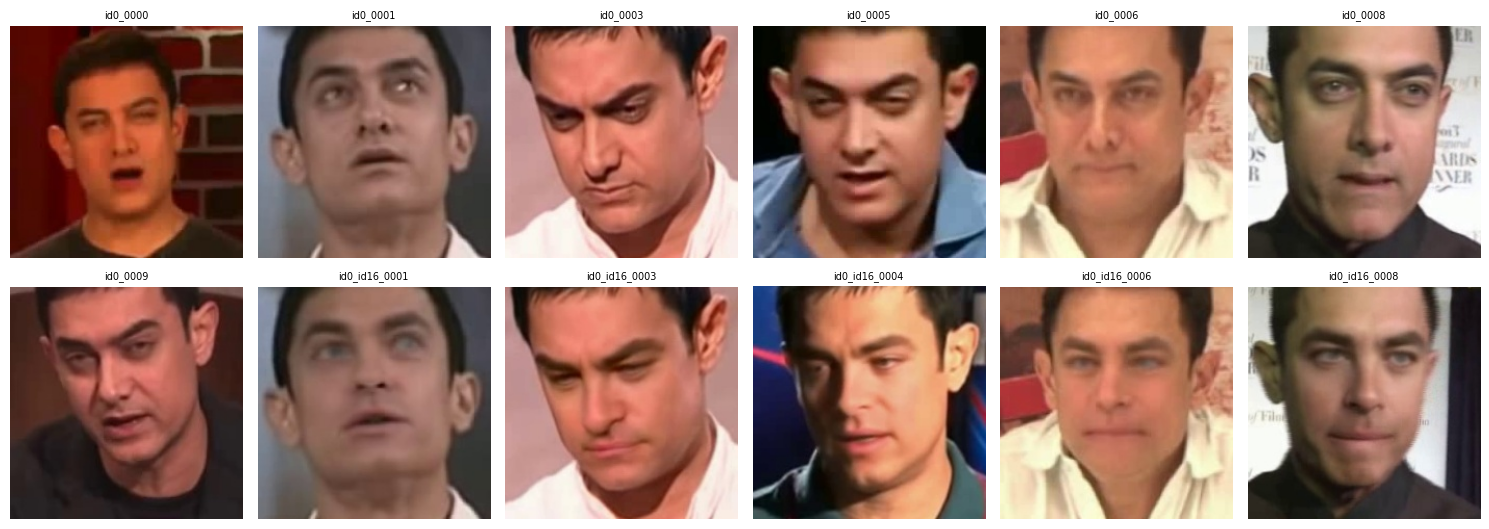

In [11]:
# Eyeball a few crops -- are they tight, upright, actually faces?
import matplotlib.pyplot as plt, cv2
from pathlib import Path

jpgs = sorted(Path("/kaggle/working/_smoke").rglob("*.jpg"))
print(len(jpgs), "crops")
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, p in zip(axes.ravel(), jpgs[:: max(1, len(jpgs) // 12)]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    ax.set_title(p.parent.name[:18], fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Full extraction

The long one. Safe to re-run after a disconnect.

In [12]:
!python -m src.data.extract_faces \
    --root {ROOT} --out /kaggle/working/faces \
    --frames 32 --size 224 --workers 4

I0000 00:00:1795224393.845216     403 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795224396.022582     403 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
videos=6229  frames/video=32  detector=mediapipe  workers=4  -> /kaggle/working/faces
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7a0f2c003220, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7a0f2c004a70, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized d

## 5. Build the split manifests

In [13]:
from src.data.splits import build_splits, summarise

m = build_splits(ROOT, "/kaggle/working/faces/splits.json")
print(summarise(m))

videos=6229  real=590  fake=5639  identities=59  key=source
  [random]
    train videos= 3738 (60.0%)  real= 354 fake= 3384  identities= 59
    val   videos= 1183 (19.0%)  real= 112 fake= 1071  identities= 58
    test  videos= 1308 (21.0%)  real= 124 fake= 1184  identities= 59
    train/test identity overlap: 59
  [identity]
    train videos= 3720 (59.7%)  real= 366 fake= 3354  identities= 36
    val   videos= 1087 (17.5%)  real= 104 fake=  983  identities= 11
    test  videos= 1422 (22.8%)  real= 120 fake= 1302  identities= 12
    train/test identity overlap: 0


## 6. Pack for distribution

~200k loose files is painful for Kaggle to save and slow for Colab to fetch.
A single tar copies to Colab's local SSD in a couple of minutes.

In [14]:
!cd /kaggle/working && tar -cf faces.tar faces && ls -lh faces.tar
!find /kaggle/working/faces -name '*.jpg' | wc -l

-rw-r--r-- 1 root root 2.3G Nov 21 01:43 faces.tar
197788


Now *Save Version > Save & Run All*, then publish the output as a **private
Kaggle dataset**. Every Colab account pulls it with:

```bash
kaggle datasets download -d <you>/celebdf-hfc-faces -p /content --unzip
tar -xf /content/faces.tar -C /content
```

In [ ]:
import json
import shutil
import getpass
from pathlib import Path

k = Path("/root/.kaggle")
k.mkdir(parents=True, exist_ok=True)

(k / "kaggle.json").write_text(json.dumps({
    "username": "rahulbhat05",
    "key": getpass.getpass("Kaggle key (the part after KGAT_): ")
}))

(k / "kaggle.json").chmod(0o600)

ds = Path("/kaggle/working/ds")
ds.mkdir(exist_ok=True)

if Path("/kaggle/working/faces.tar").exists():
    shutil.move("/kaggle/working/faces.tar", ds / "faces.tar")

(ds / "dataset-metadata.json").write_text(json.dumps({
    "title": "celebdf-hfc-faces",
    "id": "rahulbhat05/celebdf-hfc-faces",
    "licenses": [{"name": "CC0-1.0"}],
}))

!pip install -q --upgrade kaggle
!kaggle datasets create -p /kaggle/working/ds